# The cold hand in college golf

**One question:** after a good or bad hole, does the next hole follow?

**One method:** score every hole as a z-score against the player's own skill and volatility,
then compare real hole order with shuffled hole order.

**One answer:** a bad hole carries over (cold hand); a good hole doesn't (no hot hand).

Five figures, saved to `poster/figures/` as `cold_*.png` and `.pdf`:

| poster box | figure |
|---|---|
| Data | `cold_1_who` (players' scoring averages), `cold_2_vs_pga` (D3 vs the PGA Tour) |
| Methods | `cold_3_shuffle` (how the shuffle works) |
| Results | `cold_4_association` (real vs shuffled), `cold_5_cold_hand` (the headline) |

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

ROOT    = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "poster" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]
N_HOLES, MIN_FIELD, MIN_ROUNDS = 18, 10, 10
N_SHUFFLE, N_BOOT = 200, 1000
rng = np.random.default_rng(2026)

# PGA Tour 2014, from Elmore & Urbaczewski (2018)
PGA = pd.DataFrame({"avg_to_par": {3: 0.065, 4: 0.051, 5: -0.323},
                    "bob": {3: 0.127, 4: 0.152, 5: 0.385}, "bow": {3: 0.187, 4: 0.205, 5: 0.105}})

installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = "Glacial Indifference" if "Glacial Indifference" in installed else "Times New Roman"
RED, BLUE, GRAY, LIGHT, INK = "#B22A36", "#2F6DB5", "#6E6E6E", "#C4C4C4", "#1a1a1a"
sns.set_theme(context="talk", style="whitegrid", font=FONT, rc={
    "figure.constrained_layout.use": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.titlelocation": "left", "axes.titlesize": 15, "axes.titlecolor": "#5f5f5f",
    "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14,
    "legend.frameon": False, "grid.color": "#e9e9e9", "figure.dpi": 90})

def finish(fig, name, title):
    "Bold takeaway title, then save a 300-dpi PNG and a PDF."
    fig.suptitle(title, x=0.01, ha="left", fontsize=21, fontweight="bold", color=INK)
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"cold_{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

sgn = lambda v, d=3: f"{v:+.{d}f}".replace("-", "−")

## 1. Data

Clean hole-by-hole scores from `notebooks/01_cleaning.ipynb`. That notebook runs 60 tests,
removes copied, duplicated and fabricated cards, and keeps or drops rounds whole.

**Strokes gained (SG)** on each hole is the average score of everyone *else* on that course
that day, minus the player's score. Positive means the player beat the field.

**Sample:** D3 men, stroke-play tournaments (no duals), fields of 10+, players with 10+
rounds.

In [2]:
holes = pd.read_parquet(ROOT / "data" / "clean" / "d3_clean_holes.parquet")
g = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["score"]
holes["sg"] = (g.transform("sum") - holes["score"]) / (g.transform("size") - 1) - holes["score"]

rounds = holes.iloc[::N_HOLES].reset_index(drop=True)
par6 = (holes["par"].to_numpy().reshape(-1, N_HOLES) == 6).any(axis=1)
keep = ((rounds["team_gender"].astype(str) == "Men") & (rounds["tournament_level"].astype(str) == "TOURNAMENT")
        & ~rounds["is_match_name"] & (rounds["field_size"] >= MIN_FIELD)).to_numpy() & ~par6
n_per_player = rounds[keep].groupby("player_id").size()
keep &= rounds["player_id"].map(n_per_player).fillna(0).to_numpy() >= MIN_ROUNDS

R = rounds[keep].reset_index(drop=True)
mat = lambda col: holes.loc[np.repeat(keep, N_HOLES), col].to_numpy().reshape(-1, N_HOLES)
SG, PAR, TO_PAR = mat("sg"), mat("par"), mat("to_par")
PLAYERS, PIDX = np.unique(R["player_id"].to_numpy(), return_inverse=True)

assert np.isin(PAR, [3, 4, 5]).all() and (R.groupby("player_id").size() >= MIN_ROUNDS).all()
print(f"{len(PLAYERS):,} players | {R['school_id'].nunique()} schools | {R['tournament_id'].nunique():,} tournaments | "
      f"{len(R):,} rounds | {SG.size:,} holes | seasons {R['season_label'].astype(str).min()} to {R['season_label'].astype(str).max()}")

3,401 players | 290 schools | 1,089 tournaments | 87,937 rounds | 1,582,866 holes | seasons 2023-24 to 2025-26


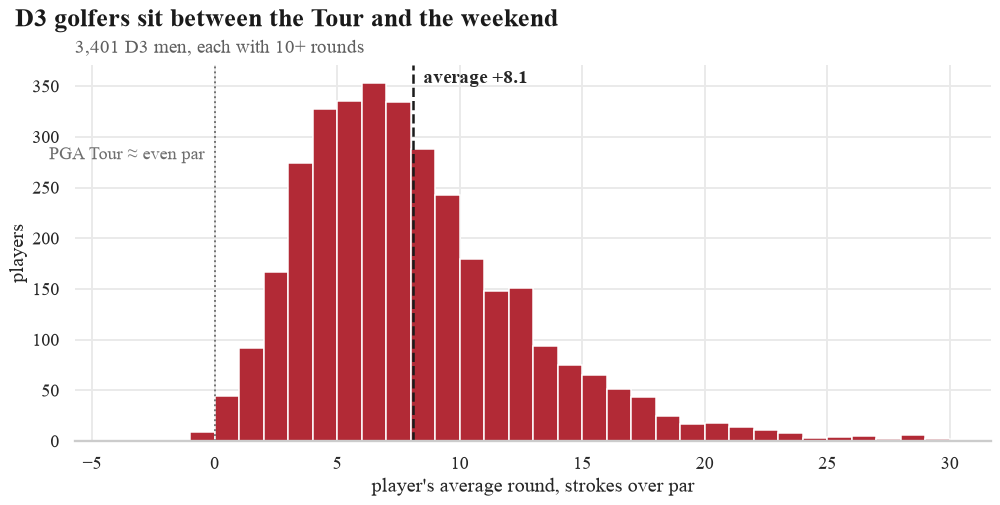

In [3]:
# ---- Figure 1: who these golfers are ----
avg = pd.Series(TO_PAR.sum(1)).groupby(PIDX).mean()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(avg, bins=np.arange(-4, 30.5, 1), color=RED, edgecolor="white", linewidth=1.2)
ax.axvline(avg.mean(), color=INK, lw=2, ls="--")
ax.annotate(f"average {sgn(avg.mean(), 1)}", (avg.mean(), 1), xycoords=("data", "axes fraction"),
            xytext=(8, -4), textcoords="offset points", va="top", fontsize=15, fontweight="bold")
ax.axvline(0, color=GRAY, lw=1.5, ls=":")
ax.annotate("PGA Tour ≈ even par", (0, 0.75), xycoords=("data", "axes fraction"), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=14, color=GRAY)
ax.set_xlabel("player's average round, strokes over par"); ax.set_ylabel("players")
ax.set_title(f"{len(avg):,} D3 men, each with {MIN_ROUNDS}+ rounds", pad=10)
finish(fig, "1_who", "D3 golfers sit between the Tour and the weekend")

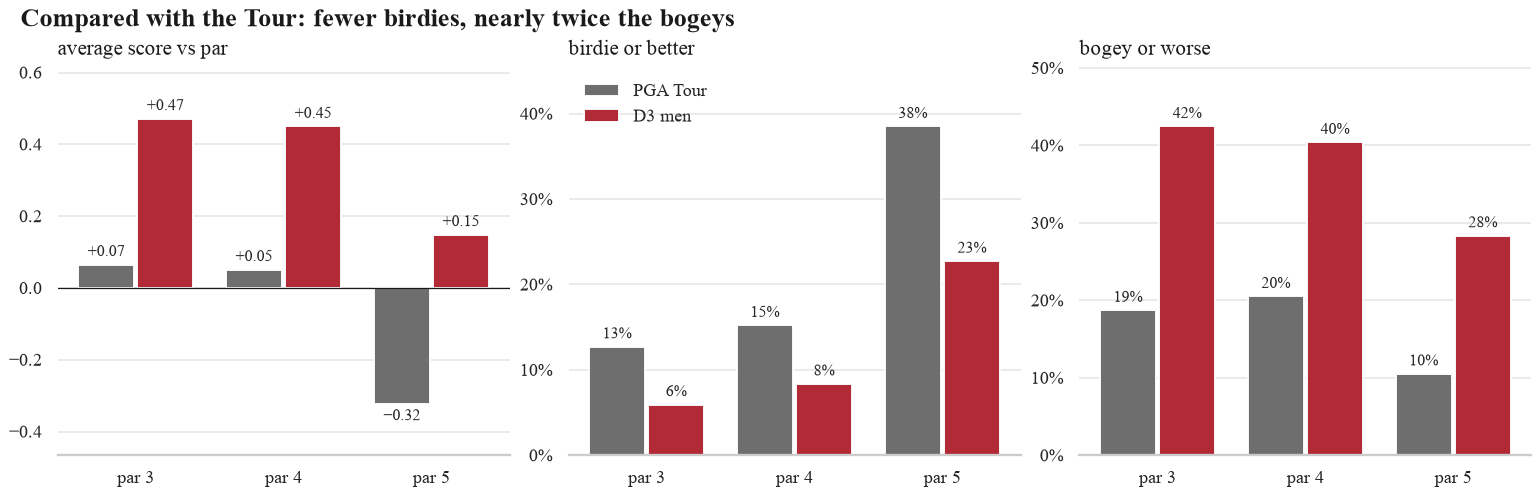

          D3                      PGA              
  avg_to_par    bob    bow avg_to_par    bob    bow
3      0.472  0.059  0.424      0.065  0.127  0.187
4      0.450  0.083  0.404      0.051  0.152  0.205
5      0.148  0.227  0.283     -0.323  0.385  0.105


In [4]:
# ---- Figure 2: D3 vs the PGA Tour, by par type ----
tp, par = TO_PAR.ravel(), PAR.ravel()
D3 = pd.DataFrame({"avg_to_par": pd.Series(tp).groupby(par).mean(),
                   "bob": pd.Series(tp <= -1).groupby(par).mean(), "bow": pd.Series(tp >= 1).groupby(par).mean()})
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, (k, title, f) in zip(axes, [("avg_to_par", "average score vs par", lambda v: sgn(v, 2)),
                                     ("bob", "birdie or better", lambda v: f"{v:.0%}"),
                                     ("bow", "bogey or worse", lambda v: f"{v:.0%}")]):
    x = np.arange(3)
    for off, src, col, lab in [(-0.2, PGA, GRAY, "PGA Tour"), (0.2, D3, RED, "D3 men")]:
        vals = src.loc[[3, 4, 5], k].to_numpy()
        ax.bar(x + off, vals, 0.38, color=col, edgecolor="white", linewidth=1.5, label=lab)
        for xi, v in zip(x + off, vals):
            ax.annotate(f(v), (xi, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                        ha="center", va="bottom" if v >= 0 else "top", fontsize=13)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks(x); ax.set_xticklabels(["par 3", "par 4", "par 5"]); ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=17, color=INK, pad=10); ax.margins(y=0.18)
    if k != "avg_to_par":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(loc="upper left")
finish(fig, "2_vs_pga", "Compared with the Tour: fewer birdies, nearly twice the bogeys")
print(pd.concat({"D3": D3, "PGA": PGA}, axis=1).round(3).to_string())

## 2. Method: the z-score

1. **Skill and volatility.** For each player, the mean (skill) and standard deviation
   (volatility) of their strokes gained on par 3s, par 4s and par 5s separately. Both come from
   the player's *other* rounds, so a hole is never part of its own baseline.
2. **z-score each hole:** $z = (\text{SG} - \text{skill}) / \text{volatility}$. A $z$ of +1 means one of
   *this player's own* standard deviations better than usual on that type of hole.
3. **Pair each hole with the next one** in the same nine (1→2 … 8→9, 10→11 … 17→18). With no tee
   times, 9→10 may not be back to back.
4. **Shuffle.** Repeat the analysis with the holes of each nine in random order, 200 times. The
   shuffle keeps the player and the day and breaks only the sequence. **Momentum = real −
   shuffled.** 95% intervals come from resampling whole players.

In [5]:
Z = np.zeros(SG.shape)
for p in (3, 4, 5):
    on_p = PAR == p
    x = np.where(on_p, SG, 0.0)
    n_r, s_r, ss_r = on_p.sum(1), x.sum(1), (x ** 2).sum(1)                        # this round
    n_p, s_p, ss_p = (np.bincount(PIDX, v, len(PLAYERS)) for v in (n_r, s_r, ss_r))  # whole career
    n_o, s_o, ss_o = n_p[PIDX] - n_r, s_p[PIDX] - s_r, ss_p[PIDX] - ss_r            # other rounds
    skill = s_o / n_o
    volatility = np.sqrt((ss_o - n_o * skill ** 2) / (n_o - 1))
    Z = np.where(on_p, (SG - skill[:, None]) / volatility[:, None], Z)

assert np.isfinite(Z).all()
print(f"z: mean {Z.mean():+.3f}, SD {Z.std():.3f}  (should be about 0 and 1)")

A = np.array([h for h in range(17) if h != 8])     # hole h ...
B = A + 1                                            # ... and the next hole, same nine

def shuffle(M):
    "Random order of the holes inside each nine, for every round."
    out = M.copy()
    for s in (slice(0, 9), slice(9, 18)):
        out[:, s] = np.take_along_axis(M[:, s], rng.random(M[:, s].shape).argsort(1), 1)
    return out

z: mean -0.003, SD 1.019  (should be about 0 and 1)


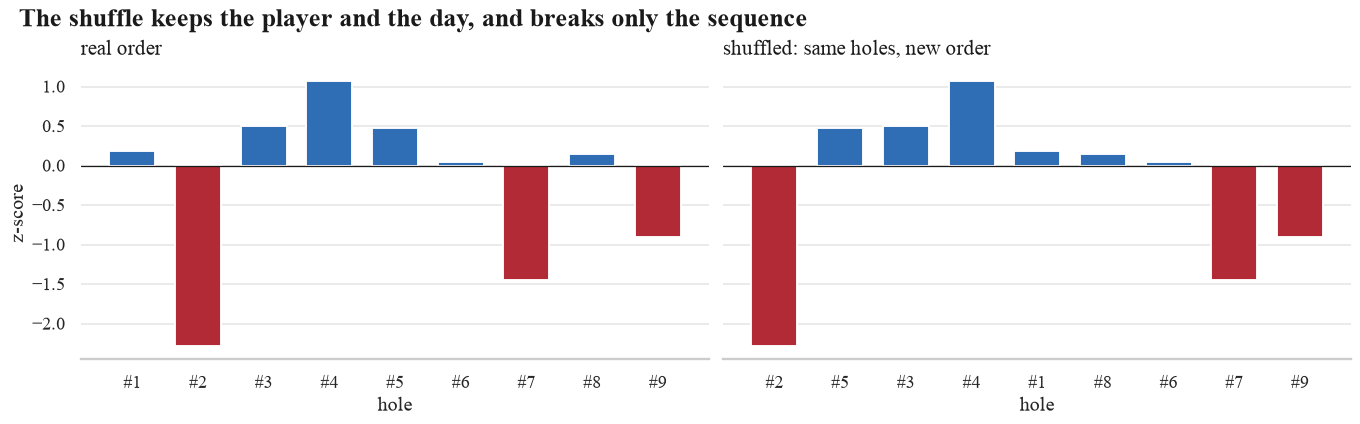

In [6]:
# ---- Figure 3: what the shuffle does, on one real nine ----
i = np.random.default_rng(4).choice(np.flatnonzero((TO_PAR[:, :9] >= 2).any(1) & (TO_PAR[:, :9] <= -1).any(1)))
order = np.random.default_rng(5).permutation(9)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, vals, labels, title in [(axes[0], Z[i, :9], np.arange(1, 10), "real order"),
                                (axes[1], Z[i, :9][order], order + 1, "shuffled: same holes, new order")]:
    ax.bar(np.arange(9), vals, color=np.where(vals >= 0, BLUE, RED), width=0.7)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks(np.arange(9)); ax.set_xticklabels([f"#{h}" for h in labels]); ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=17, color=INK, pad=10); ax.set_xlabel("hole")
axes[0].set_ylabel("z-score")
finish(fig, "3_shuffle", "The shuffle keeps the player and the day, and breaks only the sequence")

## 3. Results

Bucket every hole by its z-score and look at the average z-score on the next hole, in real
order and in shuffled order.

In [7]:
EDGES = [-2, -1, -0.5, 0.5, 1, 2]
BUCKETS = ["≤ −2", "−2 to −1", "−1 to −0.5", "about\naverage", "0.5 to 1", "1 to 2", "≥ 2"]

def bucket_sums(M):
    "Per round: count and sum of next-hole z, by bucket of this-hole z."
    k = np.digitize(M[:, A], EDGES)
    rows = np.repeat(np.arange(len(M)), len(A))
    cnt, tot = np.zeros((len(M), 7)), np.zeros((len(M), 7))
    np.add.at(cnt, (rows, k.ravel()), 1)
    np.add.at(tot, (rows, k.ravel()), M[:, B].ravel())
    return cnt, tot

cnt, tot = bucket_sums(Z)
real = tot.sum(0) / cnt.sum(0)
shuffled_runs = np.array([(lambda c, t: t.sum(0) / c.sum(0))(*bucket_sums(shuffle(Z))) for _ in range(N_SHUFFLE)])
shuffled = shuffled_runs.mean(0)

# resample whole players for the 95% interval of real − shuffled
P_cnt = np.zeros((len(PLAYERS), 7)); np.add.at(P_cnt, PIDX, cnt)
P_tot = np.zeros((len(PLAYERS), 7)); np.add.at(P_tot, PIDX, tot)
W = np.stack([np.bincount(rng.integers(0, len(PLAYERS), len(PLAYERS)), minlength=len(PLAYERS)) for _ in range(N_BOOT)])
boot = (W @ P_tot) / (W @ P_cnt) - shuffled
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
p = [(1 + (np.abs(shuffled_runs[:, j] - shuffled[j]) >= abs(real[j] - shuffled[j])).sum()) / (1 + N_SHUFFLE) for j in range(7)]

RESULTS = pd.DataFrame({"this hole (z)": [b.replace("\n", " ") for b in BUCKETS], "pairs": cnt.sum(0).astype(int),
                        "next hole, real": real, "next hole, shuffled": shuffled, "momentum": real - shuffled,
                        "95% low": lo, "95% high": hi, "shuffle p": p})
print(RESULTS.round(4).to_string(index=False))

this hole (z)  pairs  next hole, real  next hole, shuffled  momentum  95% low  95% high  shuffle p
         ≤ −2  54881          -0.0951              -0.0773   -0.0179  -0.0270   -0.0087     0.0050
     −2 to −1 151321          -0.0574              -0.0536   -0.0038  -0.0092    0.0017     0.0995
   −1 to −0.5 187566          -0.0303              -0.0264   -0.0040  -0.0081    0.0002     0.0896
about average 570241          -0.0061              -0.0090    0.0029   0.0008    0.0050     0.0100
     0.5 to 1 268624           0.0353               0.0344    0.0009  -0.0026    0.0044     0.5920
       1 to 2 155885           0.0521               0.0482    0.0040  -0.0014    0.0089     0.0597
          ≥ 2  18474           0.0721               0.0886   -0.0165  -0.0307   -0.0008     0.0199


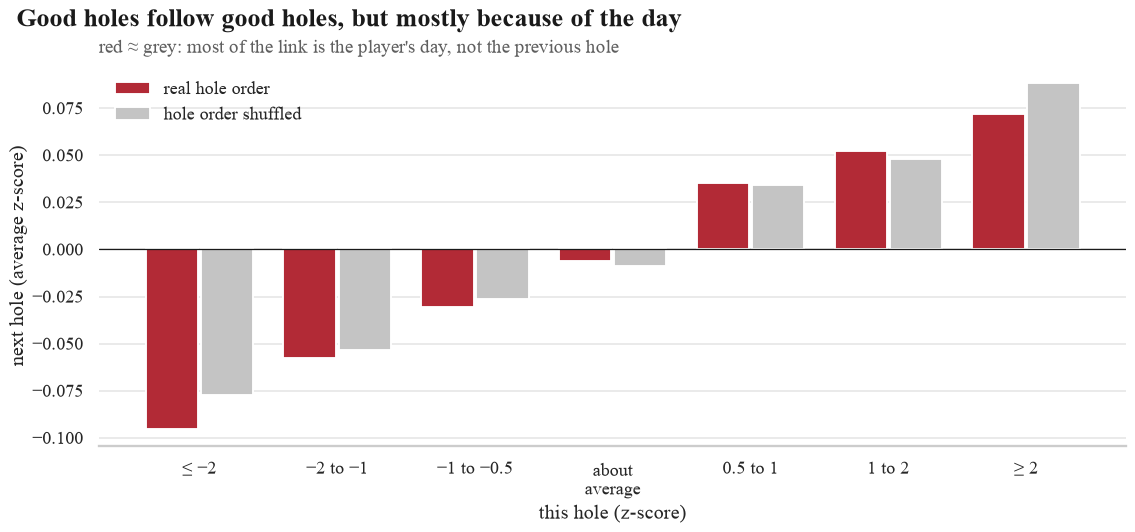

In [8]:
# ---- Figure 4: the association, real vs shuffled ----
fig, ax = plt.subplots(figsize=(12.5, 5.8))
x = np.arange(7)
ax.bar(x - 0.2, real, 0.38, color=RED, edgecolor="white", linewidth=1.5, label="real hole order")
ax.bar(x + 0.2, shuffled, 0.38, color=LIGHT, edgecolor="white", linewidth=1.5, label="hole order shuffled")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(x); ax.set_xticklabels(BUCKETS); ax.grid(axis="x", visible=False)
ax.set_xlabel("this hole (z-score)"); ax.set_ylabel("next hole (average z-score)")
ax.set_title("red ≈ grey: most of the link is the player's day, not the previous hole", pad=10)
ax.legend(loc="upper left")
finish(fig, "4_association", "Good holes follow good holes, but mostly because of the day")

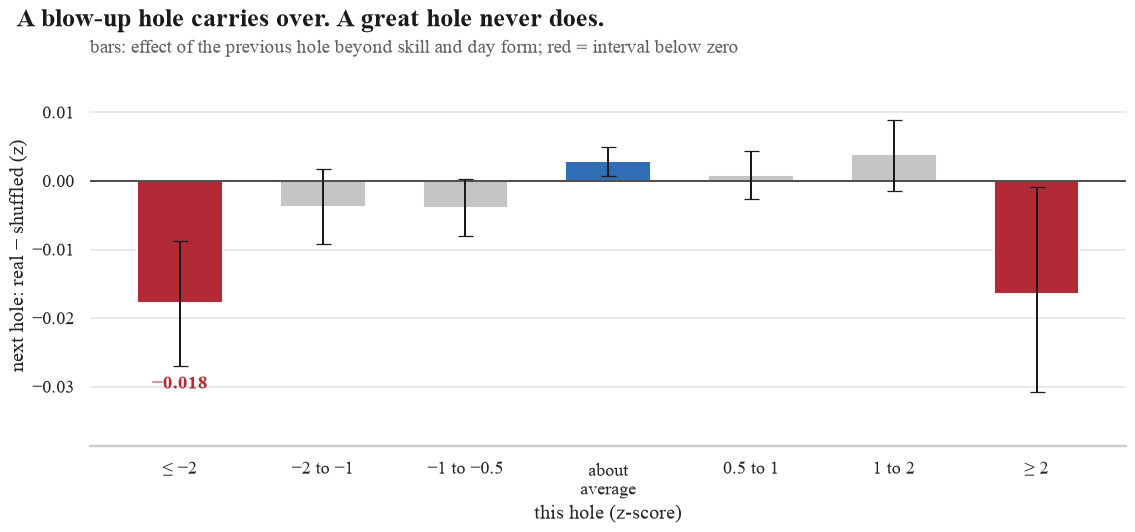

In [9]:
# ---- Figure 5: the headline, momentum = real − shuffled ----
mom = real - shuffled
sig = (lo > 0) | (hi < 0)
colors = [RED if s and m < 0 else (BLUE if s else LIGHT) for s, m in zip(sig, mom)]
fig, ax = plt.subplots(figsize=(12.5, 5.8))
ax.bar(x, mom, 0.6, color=colors, edgecolor="white", linewidth=1.5)
ax.errorbar(x, mom, yerr=[mom - lo, hi - mom], fmt="none", ecolor=INK, capsize=6, lw=1.6)
ax.axhline(0, color=INK, lw=1.2)
j = 0
ax.annotate(f"{sgn(mom[j])}", (x[j], lo[j]), xytext=(0, -8), textcoords="offset points", ha="center", va="top",
            fontsize=15, fontweight="bold", color=RED)
ax.set_xticks(x); ax.set_xticklabels(BUCKETS); ax.grid(axis="x", visible=False)
ax.set_xlabel("this hole (z-score)"); ax.set_ylabel("next hole: real − shuffled (z)")
ax.margins(y=0.2)
ax.set_title("bars: effect of the previous hole beyond skill and day form; red = interval below zero", pad=10)
finish(fig, "5_cold_hand", "A blow-up hole carries over. A great hole never does.")

## 4. Poster text (numbers from this run)

In [10]:
cold, hot = RESULTS.iloc[0], RESULTS.iloc[-1]
day_share = shuffled[0] / real[0]
print(f"""RESULTS
• Good holes follow good holes: after a blow-up hole (z ≤ −2) the next hole averages z = {sgn(real[0], 2)}; after a
  great hole (z ≥ 2), z = {sgn(real[-1], 2)}.
• Most of that is the day: with hole order shuffled the same buckets give {sgn(shuffled[0], 2)} and {sgn(shuffled[-1], 2)}.
• Cold hand: after a blow-up hole the next hole is {sgn(cold['momentum'])} SD worse than the day predicts
  (95% CI {sgn(cold['95% low'])} to {sgn(cold['95% high'])}; shuffle p = {cold['shuffle p']:.3f}).
• No hot hand: after a great hole the next hole is no better than the day predicts; if anything it is
  slightly worse ({sgn(hot['momentum'])} SD, 95% CI {sgn(hot['95% low'])} to {sgn(hot['95% high'])}), a small letdown, never a boost.

CONCLUSION
Most of what looks like momentum on a scorecard is skill and the kind of day a player is having.
Beyond both, a blow-up hole still drags down the next one, while a great hole gives nothing extra:
a cold hand without a hot hand, the same asymmetry Elmore & Urbaczewski found on the PGA Tour.
The effect is small, but in golf bad holes linger and good holes don't.""")

RESULTS
• Good holes follow good holes: after a blow-up hole (z ≤ −2) the next hole averages z = −0.10; after a
  great hole (z ≥ 2), z = +0.07.
• Most of that is the day: with hole order shuffled the same buckets give −0.08 and +0.09.
• Cold hand: after a blow-up hole the next hole is −0.018 SD worse than the day predicts
  (95% CI −0.027 to −0.009; shuffle p = 0.005).
• No hot hand: after a great hole the next hole is no better than the day predicts; if anything it is
  slightly worse (−0.016 SD, 95% CI −0.031 to −0.001), a small letdown, never a boost.

CONCLUSION
Most of what looks like momentum on a scorecard is skill and the kind of day a player is having.
Beyond both, a blow-up hole still drags down the next one, while a great hole gives nothing extra:
a cold hand without a hot hand, the same asymmetry Elmore & Urbaczewski found on the PGA Tour.
The effect is small, but in golf bad holes linger and good holes don't.
